# 1주차 · Python과 표 데이터
### 숫자의 뜻을 설명하고, 계산한 결과를 확인하기

화분 여섯 개의 기록으로 시작합니다. 한 행이 무엇을 뜻하는지 읽고, 평균과 분산을 손으로 구한 뒤 Python으로 같은 계산을 확인합니다. 마지막에는 그래프의 점 하나를 원래 표에서 찾아 설명합니다.

예제의 화분과 수치는 수업용으로 만든 합성 자료이며 실제 실험 결과가 아닙니다. 변수·조건문·반복문·함수·리스트를 써 본 학생을 위한 자료입니다. 낯선 부분은 작은 입력으로 계산을 따라가며 익힙니다.


## 오늘 풀어 볼 질문

- 한 행과 한 열은 각각 무엇을 나타낼까요? 어떤 열로 어떤 값을 예측하려는 걸까요?
- 평균은 왜 합계를 개수로 나눌까요? 같은 평균을 가진 두 묶음의 퍼짐은 어떻게 구별할까요?
- 배열의 어느 축을 줄이면 어떤 값과 모양이 남을까요?
- CSV에서 필요한 행과 열을 어떻게 고를까요? 기록 없음과 0은 왜 다를까요?
- 그래프의 점이나 막대 하나는 무엇을 뜻하며, 어디까지 해석할 수 있을까요?

먼저 예상과 이유를 적고, 예제를 실행한 결과와 비교합니다. 틀렸다면 답만 바꾸지 말고 처음 다르게 생각한 단계를 찾습니다. 답안 칸의 ‘받은 도움’에는 참고한 힌트나 설명을 적습니다.


## 노트북 사용하기

Python 3와 NumPy, pandas, Matplotlib을 사용합니다. 뒤의 추가 연습에서는 Seaborn도 사용합니다.

JupyterLab에서 셀을 선택하고 **Shift+Enter**를 누르면 실행됩니다. 글을 고치려면 Markdown 셀을 두 번 누릅니다. 코드 셀의 대괄호에 별표가 보이면 실행 중입니다. 저장은 **Ctrl+S**이며 Mac에서는 **⌘S**입니다. 처음부터 확인하려면 **Kernel → Restart Kernel and Run All Cells**를 선택합니다.

아래 준비 코드부터 위에서 아래 순서로 실행합니다. 새로 작성할 코드는 해당 문제 바로 아래에 코드 셀을 추가합니다.


In [ ]:
from pathlib import Path
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

%matplotlib inline
available_fonts = {item.name for item in font_manager.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic",
                  "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams.update({"figure.figsize": (8, 4.6), "font.size": 12,
                     "axes.unicode_minus": False, "axes.spines.top": False,
                     "axes.spines.right": False})
print("준비 완료. 이후 셀은 위에서 아래 순서로 실행합니다.")


## 표와 계산의 뜻 읽기

### 1. 한 행은 화분 하나의 기록입니다

같은 종류의 어린 식물을 서로 다른 화분에 심었다고 가정합니다. 빛을 받은 시간과 준 물의 양을 기록하고, 일주일 뒤 높이를 잽니다. 여기서는 기록 방법을 배우기 위해 만든 숫자를 사용합니다.

| 화분 번호 | 장소 | 하루 빛을 받은 시간(h) | 하루 준 물(ml) | 일주일 뒤 높이(cm) |
|---|---|---:|---:|---:|
| P01 | 실내 | 2 | 0 | 8 |
| P02 | 실내 | 3 | 20 | 10 |
| P03 | 창가 | 5 | 기록 없음 | 12 |
| P04 | 창가 | 6 | 40 | 14 |
| P05 | 실내 | 4 | 20 | 10 |
| P06 | 창가 | 7 | 60 | 18 |

한 **행**은 화분 하나의 관찰 기록이고, 한 **열**은 같은 종류의 정보입니다. 주어진 정보로 높이를 예측하는 문제라면 빛의 시간과 물의 양을 **특성(feature)**, 알아맞힐 높이를 정답(target)이라고 부릅니다. 정답이라는 말은 이 표에 기록한 비교 대상이라는 뜻입니다. 측정이 완벽하다는 뜻까지 담고 있지는 않습니다.

P01의 물 0ml는 물을 주지 않았다고 기록한 값입니다. P03의 빈칸은 물의 양을 모른다는 뜻입니다. 빈칸을 0으로 바꾸면 서로 다른 상황을 같은 값으로 만들게 됩니다. 화분 번호는 기록을 찾는 식별자입니다.

#### 한 행의 특성이 예측값이 되기까지

언제 예측하는지 먼저 정합니다. 여기서는 **일주일이 끝나고 높이를 재기 직전**, 빛 시간과 물의 양이 매일 같았고 그 기록을 이미 확인할 수 있다고 가정합니다. 새 화분에서 그 기록이 없다면 이 숫자를 입력으로 쓸 수 없습니다. 심는 날에 예측한다면 앞으로 실제로 받을 빛과 물은 아직 모를 수 있습니다. 정해진 계획을 쓸 수는 있지만 계획과 실제 기록이 같다고 단정하지 않습니다.

빛 시간의 숫자를 $L$(시간 h), 물의 양의 숫자를 $W$(ml), 예측 높이를 $\hat{y}$(cm)라고 합시다. **계산 방법을 보여 주려고 임의로 정한 식**은

$$
\hat{y} = 4 + 1\times L + 0.1\times W
$$

입니다. 4의 단위는 cm, 1의 단위는 cm/h, 0.1의 단위는 cm/ml이므로 각 항은 cm입니다. 이 수들은 위 표에서 학습하거나 실제 효과를 측정해 얻은 값이 아닙니다. 표의 높이는 나중에 예측을 비교하기 위한 값이며 예측식에 입력하지 않습니다.

P02는 빛 3h, 물 20ml이므로, 식에 넣으면 $4+1\times3+0.1\times20=4+3+2=9$cm입니다. 나중에 잰 높이 $y$는 10cm입니다. 여기서는 **실제값 − 예측값**으로 차이를 정하므로 $y-\hat{y}=10-9=+1$cm, 즉 1cm 낮게 예측했습니다. 한 행의 차이만으로 이 식이 잘 맞는지 판단하지 않습니다. 이 표로 모델을 학습하지 않으며, 식의 계수가 실제 원인이나 효과라고 주장하지도 않습니다. 나중에는 여러 행의 예측과 실제값 차이를 살펴 계수를 정하는 방법과, 새로운 자료로 확인하는 방법을 배웁니다.


### 2. 평균은 합계를 같은 몫으로 나눈 값입니다

길이가 2cm, 4cm, 6cm인 세 막대를 생각해 봅니다. 길이를 모두 모아 같은 길이의 막대 세 개로 나눈다면, 한 막대의 길이는 얼마여야 할까요?

길이의 합은 12cm입니다. 똑같이 나눈 길이를 $\bar{x}$라고 하면 $3\bar{x}=12\text{ cm}$여야 합니다. 양쪽을 3으로 나누어 $\bar{x}=4\text{ cm}$를 얻습니다. **합계를 보존하면서 같은 몫으로 나눈 값**이 산술평균입니다.

$$
\bar{x}=\frac{x_1+x_2+\cdots+x_n}{n}
       =\frac{1}{n}\sum_{i=1}^{n}x_i.
$$

| 기호 | 이 수업에서의 뜻 |
|---|---|
| $n$ | 값의 개수. 1 이상의 정수 |
| $i$ | 몇 번째 값인지 나타내는 번호. 1부터 $n$까지 |
| $x_i$ | $i$번째 값. 여기서는 cm로 잰 길이 |
| $\sum_{i=1}^{n}x_i$ | 첫 값부터 마지막 값까지 더한다는 표기 |
| $\bar{x}$ | 평균. ‘엑스 바’라고 읽으며 단위는 cm |

이 식은 유한한 숫자가 하나 이상 있고 모두 같은 종류·단위의 양일 때 사용합니다. 빈 목록은 개수 0으로 나눌 수 없어 평균이 정의되지 않습니다. 빈칸이 있는 표에서는 어떤 값을 계산에 포함할지 먼저 정해야 합니다. 물의 양(ml)과 길이(cm)를 더한 평균은 이 자료에서 해석하지 않습니다.

평균은 관측값 중 하나일 필요가 없습니다. 2cm와 3cm의 평균은 2.5cm입니다. 2cm와 6cm의 평균을 8cm라고 답했다면, 합계에서 어떤 계산을 빠뜨렸는지 찾아보세요.


### 같은 평균이어도 퍼진 정도는 다릅니다

[2, 4, 6]cm와 [4, 4, 4]cm의 평균은 모두 4cm입니다. 평균만으로는 첫 묶음의 값들이 더 퍼져 있다는 사실을 나타내기 어렵습니다.

각 값에서 평균을 뺀 $x_i-\bar{x}$를 **편차**라고 합니다. 평균보다 작으면 음수, 크면 양수이며 평균과 같으면 0입니다. 첫 묶음의 편차는 [-2, 0, 2]cm입니다. 편차를 그대로 더하면 0입니다. 이 현상은 이 예제에만 생기지 않습니다.

$$
\sum_{i=1}^{n}(x_i-\bar{x})
=\sum_{i=1}^{n}x_i-n\bar{x}=0.
$$

평균을 $n$번 빼므로 두 번째 식에 $n\bar{x}$가 나옵니다. 평균의 정의에서 $n\bar{x}=\sum_{i=1}^{n}x_i$이므로 두 양이 서로 지워집니다. 따라서 **편차의 합**으로 퍼짐을 재면 다른 길이들이 섞여 있어도 항상 0이 됩니다.

분산은 편차를 제곱한 값의 평균으로 정의합니다. 제곱하면 음수와 양수가 서로 지워지지 않고, 평균에서 멀수록 큰 값이 됩니다.

$$
v=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2.
$$

$v$는 **분산**이며 나머지 기호는 평균 식과 같습니다. 지금 가진 값 전체의 퍼짐을 기술하므로 분모를 $n$으로 정합니다. 더 큰 집단의 분산을 표본으로 추정할 때 쓰는 $n-1$ 공식과 구별합니다. 퍼짐을 재는 방법은 여러 가지이며, 여기서는 제곱한 편차의 평균을 배웁니다.

| 단계 | 2cm | 4cm | 6cm |
|---|---:|---:|---:|
| 평균 4cm를 빼기 | -2cm | 0cm | 2cm |
| 편차를 제곱하기 | 4cm² | 0cm² | 4cm² |

제곱합은 $4+0+4=8\text{ cm}^2$, 분산은 $8/3\approx2.67\text{ cm}^2$입니다. [4, 4, 4]에서는 편차가 모두 0이라 분산도 0입니다. 제곱했기 때문에 분산의 단위는 cm²이며, 길이 자체를 뜻하는 cm와 다릅니다.

왜 제곱합을 개수로 나눌까요? [2, 4, 6]을 그대로 두 번 기록하면 평균은 4cm, 제곱합은 16cm², 개수는 6입니다. 분산은 $16/6=8/3\text{ cm}^2$로 같습니다. 같은 묶음을 반복해서 기록한 것만으로 퍼짐이 커졌다고 세지 않도록 **한 값당 제곱 편차**를 구하는 것입니다.


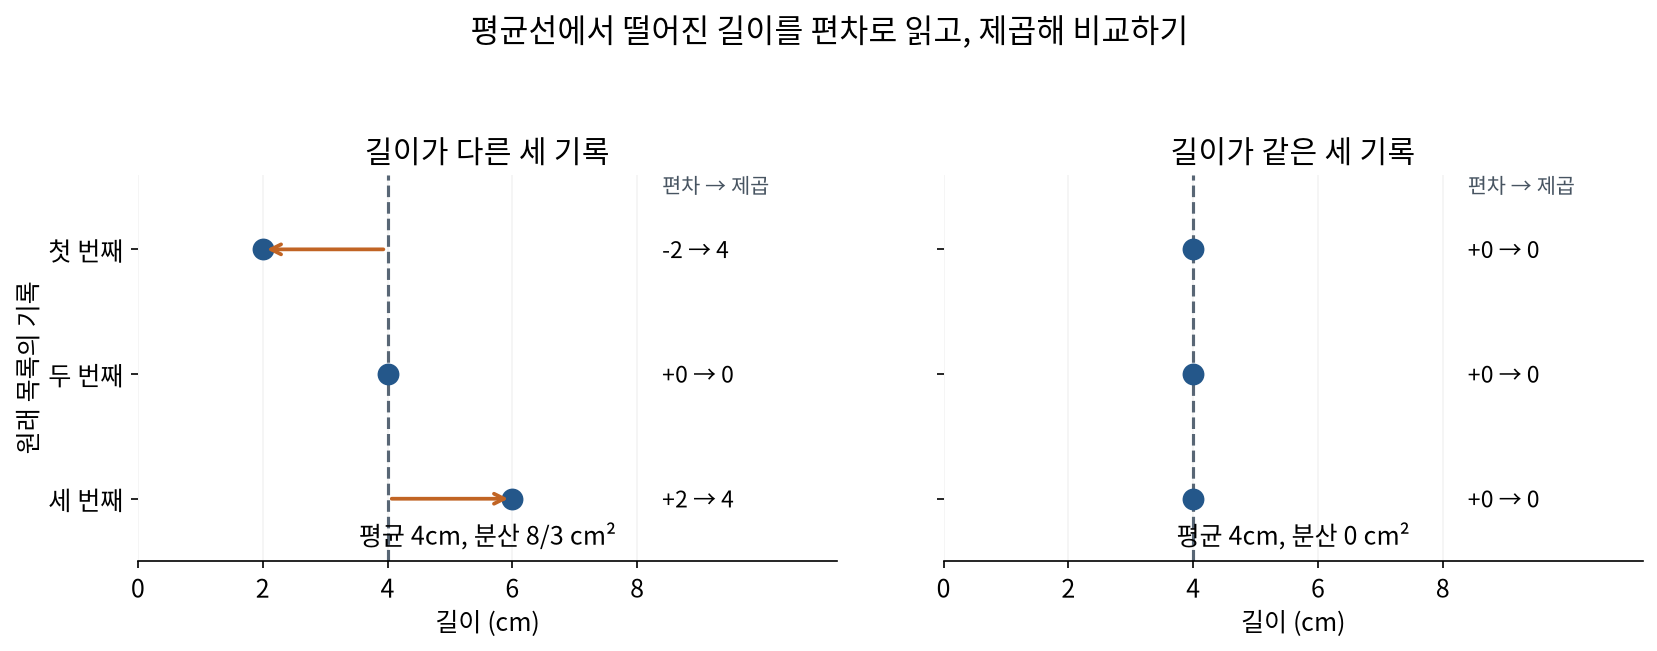

점 하나는 길이 기록 하나입니다. 가로축은 길이(cm), 세로 위치는 기록을 구별하는 순서이며 길이의 크기를 나타내지 않습니다. 점선은 평균 4cm입니다. 주황색 화살표는 평균에서 각 값으로 향하며, 방향은 편차의 부호, 가로 길이는 편차의 크기를 나타냅니다. 오른쪽 숫자의 화살표는 ‘편차(cm)를 제곱한 값(cm²)’으로 바꾼다는 뜻입니다.

오른쪽 묶음은 세 점의 가로 위치가 모두 4이지만 서로 다른 기록입니다. 왼쪽에서 가로 위치 6인 점의 편차와 제곱을 식의 어느 항에 대응시킬 수 있을까요? 두 묶음에서 평균이 같은데 분산이 다른 이유를 그림과 계산으로 설명해 보세요.

### 평균 계산을 순서로 적으면 알고리즘이 됩니다

**알고리즘**은 입력을 받아 결과를 만드는 절차입니다. 정상 입력은 같은 단위의 Python 정수 또는 유한한 실수(float) 1~10,000개로 된 목록이며, 각 값의 범위는 −1,000,000 이상 1,000,000 이하이고 빈칸은 없습니다. 출력은 같은 단위의 평균 하나입니다. 빈 목록은 평균이 정의되지 않으므로 오류로 알립니다. 이 함수는 그 밖의 범위나 자료형을 따로 검사하지 않습니다. 컴퓨터가 실수를 근삿값으로 저장하므로 계산에 작은 반올림 차이가 생길 수 있습니다.

다음은 Python 문법에 매이지 않고 순서를 적은 **의사코드**입니다.

~~~text
평균_구하기(숫자_목록):
    개수 ← 목록에 든 값의 수
    개수가 0이면 오류를 알리고 끝낸다
    합계 ← 0
    목록의 각 값을 앞에서부터 하나씩 읽는다:
        합계 ← 지금 합계 + 읽은 값
    합계 / 개수를 결과로 돌려준다
~~~

화살표 $\leftarrow$는 오른쪽 값을 왼쪽 이름에 저장한다는 뜻입니다. Python에서는 대입에 <code>=</code>, 결과를 호출한 곳으로 돌려주는 데 <code>return</code>을 씁니다.

입력이 [2, 4, 6]이면 개수는 처음부터 끝까지 3입니다. 합계가 어떻게 바뀌는지 따로 따라갑니다.

| 단계 | 읽은 값 | 더하기 전 합계 | 더한 뒤 합계 | 돌려주는 값 |
|---|---:|---:|---:|---:|
| 초기화 | 아직 없음 | | 0 | 아직 없음 |
| 첫 번째 반복 | 2 | 0 | 2 | 아직 없음 |
| 두 번째 반복 | 4 | 2 | 6 | 아직 없음 |
| 세 번째 반복 | 6 | 6 | 12 | 아직 없음 |
| 반복 끝, 반환 | 더 읽을 값 없음 | 12 | 12 | 12 / 3 = 4 |

반환할 때 합계가 4로 바뀌는 것은 아닙니다. **합계는 12이고 반환값이 4**입니다. 매번 한 값을 더한 뒤 합계는 ‘지금까지 읽은 값의 합’입니다. 세 값을 모두 읽으면 전체 합이 되므로 마지막 나눗셈이 평균의 정의와 일치합니다.

입력이 [2]라면 반복은 한 번이고 반환값은 2입니다. 입력이 []라면 초기 검사에서 끝나므로 나눗셈에 도달하지 않습니다. 분산 계산에서는 평균을 먼저 구한 뒤, 각 편차의 제곱을 누적하는 과정이 한 번 더 필요합니다.


### 3. shape는 값이 놓인 자리의 수입니다

같은 단위(cm)로 잰 길이 여섯 개를 3행 2열로 놓겠습니다.

$$
A=
\begin{bmatrix}
2&4\\
6&8\\
10&12
\end{bmatrix},
\qquad \mathrm{shape}(A)=(3,2).
$$

**shape**는 차례대로 각 축의 길이를 적은 것입니다. 이 2차원 배열의 첫 축 **axis=0** 길이는 행 수 3, 둘째 축 **axis=1** 길이는 열 수 2입니다. 수학에서는 $a_{ij}$로 $i$행 $j$열 값을 나타내며 여기서 $i=1,2,3$, $j=1,2$입니다. Python은 0부터 세므로 수학의 $a_{12}=4$는 코드의 <code>A[0, 1]</code>에 대응합니다.

평균을 구할 때 <code>axis</code>는 **어느 축을 줄일지** 지정합니다. 이 수업의 배열은 직사각형이며, 모든 값은 유한한 숫자입니다. <code>keepdims=False</code>로 줄인 축은 결과에서 사라집니다.

- <code>axis=0</code>: 행 축의 세 값을 모아 평균을 냅니다. 열마다 하나씩 남으므로 결과는 [6, 8], shape는 <code>(2,)</code>입니다.
- <code>axis=1</code>: 열 축의 두 값을 모아 평균을 냅니다. 행마다 하나씩 남으므로 결과는 [3, 7, 11], shape는 <code>(3,)</code>입니다.

<code>(2,)</code>의 쉼표는 한 축만 있는 shape 표기입니다. 2행 1열인 <code>(2, 1)</code>과는 모양이 다릅니다.


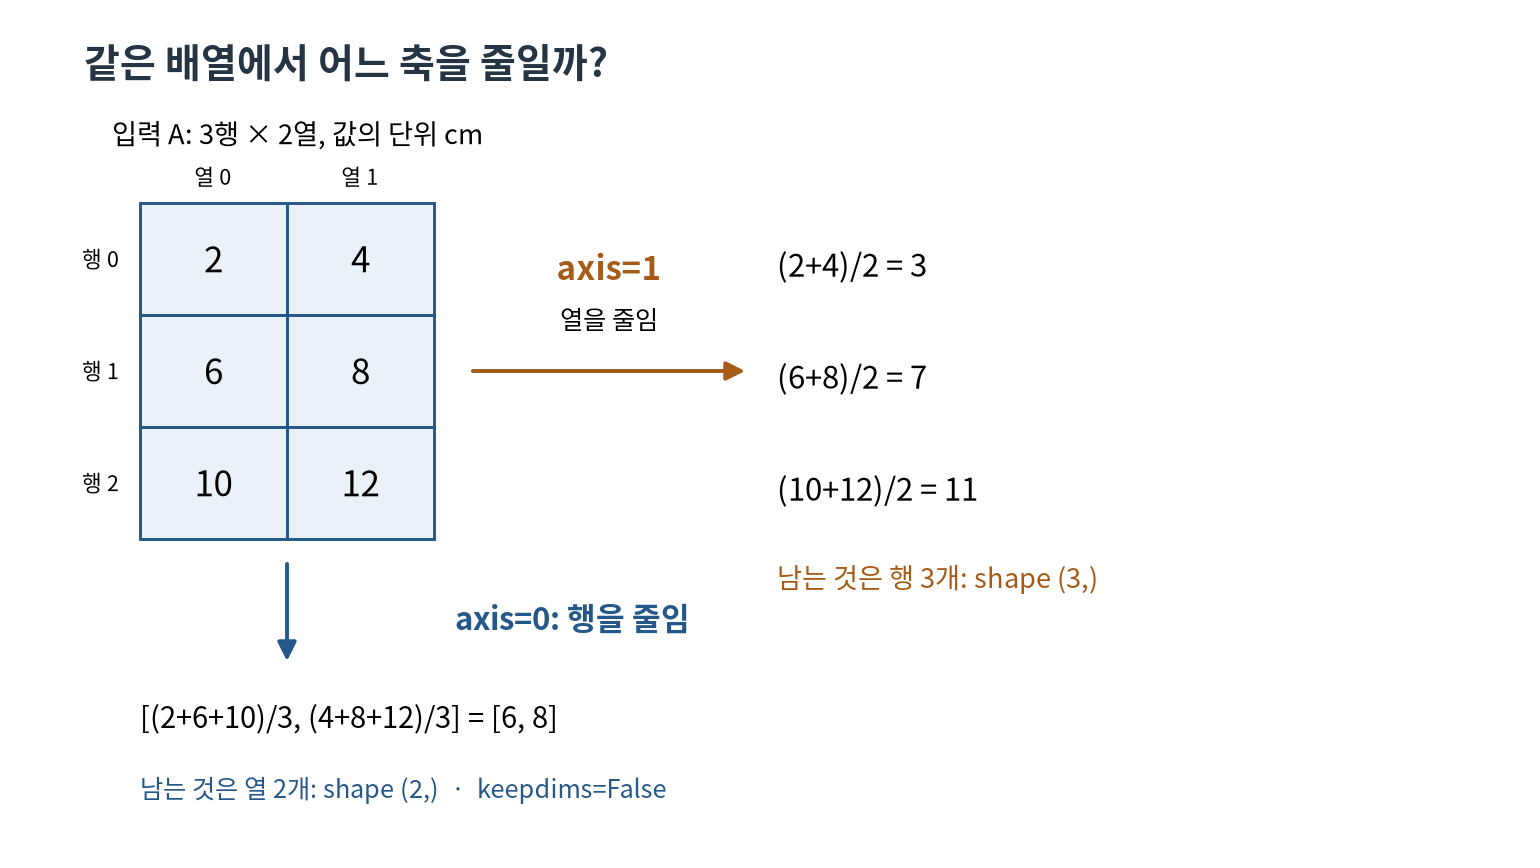

그림의 화살표 방향만 외우지 말고, 평균 하나를 만들 때 어떤 값을 묶었는지 확인합니다.

그림에서 세로로 묶인 2, 6, 10은 첫 열입니다. 이 세 수를 더해 3으로 나누면 아래의 첫 결과 6이 됩니다. 가로로 묶인 6, 8은 둘째 행이며, 두 수를 더해 2로 나누면 오른쪽의 둘째 결과 7이 됩니다. 화살표는 값이 이동한다는 뜻이 아니라 **한 묶음을 평균 하나로 바꾸는 관계**를 나타냅니다.

아래 결과 8을 만드는 원래 세 값을 찾아보세요. 오른쪽 결과 11을 만드는 값은 몇 개이며, 왜 개수가 다른가요?


#### 식과 계산 순서를 연결하기

일반적인 $m$행 $p$열 배열에서도 같습니다. $m$은 행 수, $p$는 열 수이며 둘 다 1 이상의 정수입니다. $a_{ij}$는 $i$행 $j$열 값이고 $i=1,\ldots,m$, $j=1,\ldots,p$입니다. 모든 원소는 같은 단위의 유한한 숫자입니다.

$$
c_j=\frac{1}{m}\sum_{i=1}^{m}a_{ij}\quad(j=1,\ldots,p),
\qquad
r_i=\frac{1}{p}\sum_{j=1}^{p}a_{ij}\quad(i=1,\ldots,m).
$$

$c_j$는 $j$번째 열의 평균입니다. 열 번호 $j$를 고정하고 행 번호 $i$만 바꾸어 $m$개를 더하므로 분모는 $m$입니다. $r_i$는 $i$번째 행의 평균입니다. 행을 고정하고 열 번호를 바꾸어 $p$개를 더하므로 분모는 $p$입니다. 평균의 단위는 원소의 단위와 같습니다.

배열 $A$의 첫 열은 $c_1=(2+6+10)/3=6\text{ cm}$, 둘째 행은 $r_2=(6+8)/2=7\text{ cm}$입니다. ‘열별 평균’이라고 열 수 2로 나누면 $18/2=9$가 되어 다른 값을 만듭니다. **이름이 아니라 실제로 더한 값의 개수**를 셉니다.

열별 평균 알고리즘은 평균 알고리즘을 열마다 반복한 것입니다.

~~~text
열별_평균(배열, 행 수 m, 열 수 p):
    결과 ← 빈 목록
    열 번호 j를 1부터 p까지 차례로 고른다:
        합계 ← 0
        행 번호 i를 1부터 m까지 차례로 고른다:
            합계 ← 합계 + 배열의 i행 j열 값
        결과 끝에 합계 / m을 붙인다
    결과를 돌려준다
~~~

첫 열을 읽을 때 합계는 0 → 2 → 8 → 18, 반환할 목록의 첫 값은 6입니다. 둘째 열을 시작하면 합계를 **다시 0으로 놓아** 0 → 4 → 12 → 24를 만들고 8을 붙입니다. 출력은 [6, 8]입니다. 합계를 초기화하지 않으면 앞 열의 값까지 섞입니다.

<code>axis=0</code>은 합 안에서 행 번호를 움직이는 계산입니다. 행 축 길이 $m$은 사라지고 열 개수 $p$만 남아 shape가 <code>(p,)</code>입니다. <code>axis=1</code>은 열 번호를 움직여 shape <code>(m,)</code>를 남깁니다. NumPy의 <code>mean</code>은 이 계산을 짧게 적게 해 줍니다.


### 4. 종이에 먼저 계산하기

위 배열 $A$를 보고 계산합니다. NumPy 셀은 아직 실행하지 않습니다.

1. <code>A[1, 0]</code>은 얼마인가요? 수학의 $a_{ij}$로도 적으세요.
2. 첫 열과 둘째 열을 각각 더하고 개수로 나누세요. <code>mean(axis=0)</code>의 값과 shape를 적으세요.
3. 세 행의 평균을 구하세요. <code>mean(axis=1)</code>의 값과 shape를 적으세요.
4. <code>axis</code>를 쓰지 않고 여섯 값을 모두 평균 내면 얼마인가요?

답을 구한 뒤 한 평균을 골라 분자에 포함한 값과 분모의 뜻을 친구에게 설명합니다. 서로 계산을 대조합니다.


**손풀이에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 5. 필기 문제로 확인하기

먼저 위의 설명과 예제를 가리고 각 답과 이유를 적습니다. 필요할 때만 다시 보고 어떤 도움을 받았는지도 표시합니다.

**선택형 1.** 다음 코드가 출력하는 값은 무엇인가요?

~~~python
total = 0
for value in [2, 5, 8]:
    if value >= 5:
        total = total + value
print(total)
~~~

① 15　② 13　③ 8　④ 2

**선택형 2.** NumPy 2차원 배열 `B`의 shape가 `(2, 3)`입니다. `B.mean(axis=0, keepdims=False)`의 결과는 무엇인가요?

① shape `(2,)`, 평균 하나에 값 3개　② shape `(3,)`, 평균 하나에 값 2개  
③ shape `(2, 3)`, 평균 하나에 값 6개　④ shape `(3,)`, 평균 하나에 값 3개

**서술형.** 세 화분의 물 기록이 `[0, 기록 없음, 12]`ml입니다. 기록된 값의 평균과 사용한 값의 개수를 구하세요. 세 화분 전체의 **실제** 평균도 지금 알 수 있는지 이유를 설명하세요. 기록 없음은 아직 모르는 값입니다.


**필기 세 문항에 내 말로 답하기**

선택형 1:  
선택형 2:  
서술형 계산과 이유:  
받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 6. Python에서 막히는 지점 찾기

다섯 문항을 읽고 실행 전 결과와 이유를 적습니다. 뒤의 코드 셀로 확인한 다음 다르게 예상한 첫 줄을 찾습니다. 함수나 반복문이 낯설면 앞의 합계 추적표에서 [2, 4]만 먼저 따라가 보세요.

**진단 1 · 저장된 값과 조건문**

~~~python
water = 10
water = water + 5
if water >= 15:
    label = "충분"
else:
    label = "부족"
~~~

마지막 <code>water</code>와 <code>label</code>은 무엇인가요?

**진단 2 · 반복문**

~~~python
total = 0
for value in [2, 4, 6]:
    total = total + value
~~~

반복 횟수와 매번의 <code>total</code>을 쓰세요.

**진단 3 · 반환과 화면 출력**

~~~python
def twice(value):
    return value * 2

def show_twice(value):
    print(value * 2)
~~~

<code>twice(3)</code>과 <code>show_twice(3)</code>을 변수에 저장하면 각 변수에 무엇이 들어가나요? 화면에 무엇이 보이는지도 따로 적으세요.

**진단 4 · 인덱스와 슬라이스**

~~~python
values = [8, 10, 12, 14]
chosen = values[1:3]
~~~

<code>values[0]</code>과 <code>chosen</code>은 무엇인가요? <code>values</code> 자체도 줄어들까요?

**진단 5 · 파일과 오류**

<code>pd.read_csv("data/week1_plants.csv")</code>에서 <code>FileNotFoundError</code>가 나면 무엇을 먼저 확인해야 하나요? 파일을 읽은 뒤 <code>table["height"]</code>에서 <code>KeyError: 'height'</code>가 나면 같은 방법으로 해결할 수 있을까요?

**진단 5의 새 오류 · 마지막 위치 찾기**

다음 함수의 입력은 **비어 있지 않은** 목록입니다. 코드를 실행하기 전에 오류가 난 줄과 까닭을 찾으세요.

~~~python
def last_value(values):
    return values[len(values)]

print(last_value([2, 4, 6]))
~~~

다음은 이 코드를 실행했을 때의 traceback(오류가 전해진 호출 경로)을 짧게 발췌한 것입니다.

~~~text
Traceback (most recent call last):
  File "lesson.py", line 4, in <module>
    print(last_value([2, 4, 6]))
  File "lesson.py", line 2, in last_value
    return values[len(values)]
IndexError: list index out of range
~~~

1. 오류 이름과 실제로 실패한 연산은 무엇인가요? 길이 3인 목록의 마지막 인덱스도 적습니다.
2. 이 함수가 마지막 값을 반환하도록 한 줄을 고치고, 주어진 목록과 한 원소 목록에서 각각 확인하세요. 빈 목록은 이 함수의 입력 조건 밖입니다. 예제와 해설은 먼저 가리고, 받은 도움을 답란에 표시합니다.



**Python 진단에 내 말로 답하기**

예상한 값과 traceback에서 실패한 줄·수정 방법:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


#### 예측을 적은 뒤 확인하기

화면 출력과 반환값을 서로 다른 줄에서 확인합니다. 오류 이름은 뒤의 CSV 활동에서 실제로 다시 다룹니다.


In [ ]:
water = 10
water = water + 5
if water >= 15:
    label = "충분"
else:
    label = "부족"
print("진단 1:", water, label)

total = 0
for value in [2, 4, 6]:
    total = total + value
    print("읽은 값과 누적 합계:", value, total)


In [ ]:
def twice(value):
    return value * 2

def show_twice(value):
    print(value * 2)

returned = twice(3)
shown = show_twice(3)
print("return으로 받은 값:", returned)
print("print만 한 함수에서 받은 값:", shown)
values = [8, 10, 12, 14]
print("첫 값:", values[0], "/ 선택:", values[1:3], "/ 원본:", values)


화면에 6이 보였어도 <code>show_twice</code>는 계산값을 돌려주지 않았습니다. 명시한 <code>return</code>이 없는 함수의 반환값은 <code>None</code>입니다. 뒤 계산에 쓸 값은 함수에서 돌려받아야 합니다.

평균 알고리즘을 다음처럼 Python으로 옮깁니다. <code>len</code>은 개수를 구하고, <code>raise</code>는 정한 오류를 알립니다. 앞에서 정한 개수·값 범위의 빈칸 없는 숫자 목록을 사용합니다. 범위 밖 입력을 검증하는 기능은 만들지 않습니다. 이론의 $n$, 합계, 나눗셈이 각각 어느 줄에 있는지 짚어 보세요.

예를 들어 평균이 4인 값 세 개의 합계를 다시 구하려면, **돌려받은 평균 × 개수**를 계산할 수 있습니다. 화면에 4가 보였다는 사실만으로는 이 곱셈을 할 수 없습니다. 그 값이 변수에 저장되어야 합니다.


In [ ]:
def mean_of_numbers(numbers):
    count = len(numbers)
    if count == 0:
        raise ValueError("평균을 구할 값이 하나 이상 필요합니다.")
    total = 0
    for value in numbers:
        total = total + value
    return total / count

average = mean_of_numbers([2, 4, 6])
reconstructed_total = average * 3
print("돌려받은 평균:", average)
print("평균으로 다시 구한 합계:", reconstructed_total)
try:
    mean_of_numbers([])
except ValueError as error:
    print("빈 목록을 넣었을 때:", error)


#### 함수를 고쳐 새 입력에 적용하기

예제를 가리고 [1, 3, 8]에서 합계가 어떻게 바뀌는지 적으세요. []일 때 0을 돌려주지 않는 이유도 설명합니다.

이제 평균 함수의 복사본을 고쳐 <code>shifted_mean(numbers, offset)</code>을 만드세요. 각 값에 같은 보정량 <code>offset</code>을 더한 뒤 평균을 **반환**하는 함수입니다. 숫자 목록은 앞의 개수·값 범위를 따르고, 보정량도 −1,000,000 이상 1,000,000 이하인 Python 정수 또는 유한한 float입니다. 범위 밖이나 다른 자료형은 별도로 검사하지 않습니다.

- 합계에 <code>value</code> 대신 무엇을 더해야 할까요? 개수와 빈 목록 처리는 바뀌어야 할까요?
- [1, 3, 8]과 보정량 2로 먼저 손계산한 뒤 함수를 실행합니다.
- 반환값을 <code>shifted_average</code>에 저장하고 3을 곱해 보정한 세 값의 합계와 대조합니다.
- 반환 대신 출력만 했다면 마지막 곱셈이 왜 되지 않는지 설명합니다.

막히면 원래 함수와 합계 추적표를 참고하고, 참고한 내용을 답안 칸에 적습니다.


In [ ]:
# shifted_mean(numbers, offset)을 직접 작성하고 새 입력으로 확인하세요.
# 반환값을 변수에 저장한 뒤 다른 계산에 사용해 보세요.


**함수 새 입력에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 7. CSV를 표로 읽기

이 예제의 CSV는 한 줄에 기록 하나를 쓰고, 쉼표로 열을 구분한 텍스트 파일입니다. 첫 줄에는 열 이름을 둡니다. 일반적인 CSV는 따옴표 안에 쉼표나 줄바꿈이 들어갈 수도 있어, 직접 문자열을 자르기보다 읽기 함수를 사용합니다. 이 수업의 파일은 <code>data/week1_plants.csv</code>입니다. 함께 받은 폴더를 그대로 열면 이 파일을 읽습니다. 노트북 하나만 옮긴 경우에는 아래에 포함된 같은 CSV 문자열을 읽습니다.

자료사전은 열의 뜻과 단위, 빈칸의 의미를 정리한 표입니다.

| 열 이름 | 뜻 | 단위·종류 | 이 수업의 역할 |
|---|---|---|---|
| pot_id | 화분 식별 번호 | 문자열 | 기록 찾기 |
| place | 관찰 장소 | 실내 또는 창가 | 범주 비교 |
| sunlight_hours | 하루 빛을 받은 시간 | h, 수치 | 예측에 쓸 특성 |
| water_ml | 하루 준 물 | ml, 수치, 1개 누락 | 예측에 쓸 특성 |
| height_cm | 일주일 뒤 높이 | cm, 수치 | 예측할 정답 |

<code>pd.read_csv</code>는 CSV를 pandas의 표인 <code>DataFrame</code>으로 읽습니다. 빈 물 기록은 <code>NaN</code>으로 표시됩니다. <code>NaN</code>은 결측을 나타내는 표식이며 실제 물의 양을 뜻하는 숫자가 아닙니다.

수업의 고정 예제 설명과 연결하기 위해, 같은 경로에 파일이 있으면 아래 코드가 파일을 읽은 뒤 노트북 안의 예제와 **열 순서·행 순서·각 값·결측 위치**를 비교합니다. CSV의 따옴표, 줄바꿈, `2`와 `2.0`처럼 읽은 값만 같은 표기는 허용합니다. 파일이 없을 때만 노트북에 든 예제를 사용합니다. 파일이 있으나 다르면 그 파일을 덮어쓰지 않고 이유를 알린 뒤 멈춥니다. 의도적으로 다른 자료를 실험할 때는 별도 변수에 읽어 자료사전과 문제 조건부터 다시 확인합니다.


In [ ]:
csv_text = 'pot_id,place,sunlight_hours,water_ml,height_cm\nP01,실내,2,0,8\nP02,실내,3,20,10\nP03,창가,5,,12\nP04,창가,6,40,14\nP05,실내,4,20,10\nP06,창가,7,60,18\n'


def load_verified_example_csv(path, embedded_csv):
    """고정 교안의 표를 읽습니다. 외부 파일은 확인만 하고 수정하지 않습니다."""
    path = Path(path)
    expected = pd.read_csv(StringIO(embedded_csv))
    if not path.exists():
        print("읽은 자료: 노트북에 포함된 예제 (외부 파일 없음)")
        return expected
    if not path.is_file():
        raise ValueError(f"{path}: 파일이 아닌 항목이 있어 예제를 확인할 수 없습니다.")
    try:
        actual = pd.read_csv(path)
    except (OSError, UnicodeError, pd.errors.ParserError, ValueError) as error:
        raise ValueError(f"{path}: CSV를 읽을 수 없습니다. 파일과 인코딩을 확인하세요.") from error
    try:
        pd.testing.assert_frame_equal(actual, expected, check_dtype=False, check_exact=True)
    except AssertionError:
        raise ValueError(
            f"{path}: 수업 예제와 다릅니다. 열·행 순서, 값과 빈칸을 확인하세요. "
            "파일은 수정하지 않았습니다. 다른 자료는 별도 변수에 읽어 실험하세요."
        ) from None
    print("읽은 자료:", path, "(노트북 예제와 값·순서 확인)")
    return actual


csv_path = Path("data/week1_plants.csv")
plants = load_verified_example_csv(csv_path, csv_text)
display(plants)

표가 열렸다면 먼저 <code>shape</code>, <code>columns</code>, <code>dtypes</code>를 봅니다. <code>dtypes</code>는 각 열의 저장 자료형입니다. 수치 열을 문자열로 읽었다면, 문자나 단위가 섞였는지 원자료부터 확인합니다. 결측 때문에 정수처럼 보이는 값이 소수 자료형으로 읽히는 일도 있습니다. 자료형의 정확한 표시 이름은 pandas 버전에 따라 조금 달라질 수 있습니다.


In [ ]:
print("행 수와 열 수:", plants.shape)
print("열 이름:", list(plants.columns))
display(plants.dtypes.rename("저장 자료형").to_frame())


### 8. 행과 열을 따로 고르기

<code>plants[["sunlight_hours", "water_ml"]]</code>는 두 열을 고릅니다. 대괄호 안의 열 이름 목록이 새 표의 열 순서도 정합니다.

<code>plants["sunlight_hours"] >= 5</code>는 각 행에 대해 조건이 맞는지 <code>True</code> 또는 <code>False</code>로 답합니다. <code>.loc[행 조건, 열 목록]</code>에 넣으면 그 조건을 만족한 행과 지정한 열을 함께 고릅니다.

먼저 빛이 5h 이상인 화분 번호와 예상 행 수를 종이에 적으세요. 그다음 아래 셀을 실행합니다.

이 조건 목록을 **불리언 마스크**라고도 부릅니다. <code>True</code>는 ‘이 행을 남긴다’, <code>False</code>는 ‘남기지 않는다’는 뜻입니다. 원래 순서의 빛 시간이 [2, 3, 5, 6, 4, 7]이면 조건은 [False, False, True, True, False, True]입니다. P03, P04, P06을 남긴 뒤 요청한 세 열을 고릅니다. 따라서 결과는 3행 3열입니다.


In [ ]:
feature_columns = ["sunlight_hours", "water_ml"]
features = plants[feature_columns]
target = plants["height_cm"]
print("특성 표 shape:", features.shape)
print("정답 열 shape:", target.shape)

enough_light = plants["sunlight_hours"] >= 5
display(pd.DataFrame({"화분 번호": plants["pot_id"], "빛 5h 이상": enough_light}))
display(plants.loc[enough_light, ["pot_id", "sunlight_hours", "height_cm"]])


특성 표에는 여섯 화분과 두 열의 자리가 있으므로 <code>features.shape</code>는 (6, 2)입니다. 정답은 화분마다 높이 하나여서 <code>target.shape</code>는 (6,)입니다. 열을 고를 때도 높이 열을 특성에 넣지 않았는지 확인합니다.

직접 고쳐 볼 때는 원본 <code>plants</code>를 덮어쓰지 말고 새 이름에 결과를 저장합니다. 조건을 6h 이상으로 바꾸면 어느 행의 True가 False로 바뀌는지 찾고, 결과의 행 수와 열 수를 설명하세요.

<code>plants["height_cm"]</code>는 한 축짜리 <code>Series</code>여서 shape가 (6,)입니다. <code>plants[["height_cm"]]</code>는 열 하나를 가진 <code>DataFrame</code>이라 (6, 1)입니다. 값이 여섯 개라는 점은 같지만 자료의 모양은 다릅니다. 빈 물 값도 표의 한 자리를 차지하므로 결측 하나가 있다고 shape가 줄어들지는 않습니다.


**행·열 선택에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 9. 모르는 값과 0을 구분하기

<code>isna()</code>는 결측인 자리를 <code>True</code>로 표시합니다. 그 결과를 <code>sum()</code>으로 더하면 <code>True</code>를 1로 세어 열별 결측 개수를 구합니다. 원래 관측값의 합을 구하는 것이 아니라, 결측 여부를 센다는 점에 주의합니다.


In [ ]:
missing_counts = plants.isna().sum()
display(missing_counts.rename("결측 개수").to_frame())
display(plants.loc[plants["water_ml"].isna(), ["pot_id", "water_ml"]])
display(plants.loc[plants["water_ml"] == 0, ["pot_id", "water_ml"]])


물 기록은 0, 20, 결측, 40, 20, 60ml입니다. **기록된 다섯 값의 평균**은 $(0+20+40+20+60)/5=28$ml입니다. 여섯 화분 전체의 실제 평균은 빈칸의 값을 알기 전에는 구할 수 없습니다.

pandas의 <code>mean()</code>은 기본적으로 결측을 제외합니다. 분모를 숨기지 않도록 개수도 함께 출력합니다. 이번 주에는 결측을 탐지하고 계산에 포함한 범위를 밝힙니다. 빈칸을 채우는 전처리와 그 값을 정할 데이터 분할은 2주차에 다룹니다.

<code>dropna()</code>로 만든 <code>recorded_water</code>는 계산용 목록이며 원래 표의 행을 지우지 않습니다. 값이 전부 결측이라면 포함할 값의 개수가 0입니다. 이 경우 평균을 0ml라고 말하지 않고 ‘계산할 관측값이 없음’이라고 설명해야 합니다.


In [ ]:
recorded_water = plants["water_ml"].dropna()
print("기록된 물 값의 개수:", len(recorded_water))
print("기록된 물 값의 합(ml):", recorded_water.sum())
print("기록된 값의 평균(ml):", recorded_water.mean())
print("원래 표의 결측 개수:", plants["water_ml"].isna().sum())


### 10. 열 이름이 바뀌었을 때

<code>FileNotFoundError</code>는 파일 위치부터 살핍니다. <code>KeyError</code>는 읽은 표에 요청한 열이 있는지 확인합니다. 두 오류는 실패한 단계가 다릅니다.

아래 함수는 필요한 열이 빠졌으면 어떤 열이 없는지 알립니다. <code>column not in table.columns</code>는 그 열 이름이 표에 없는지 검사합니다. 모르는 열을 조용히 빈 값으로 만들어 계속하지 않습니다.

열 검사 함수의 입력은 표와 필요한 열 이름 목록입니다. 표에 모두 있으면 **요청한 순서의 열을 가진 새 표**를 돌려줍니다. 하나라도 없으면 그 이름을 담은 <code>KeyError</code>로 멈춥니다. 예를 들어 요청이 ["pot_id", "height"]이면 빈 목록에서 시작해 "pot_id"에서는 그대로, "height"에서는 ["height"]로 바뀌므로 선택 단계에 도달하지 않습니다. 오류가 나면 임의의 이름을 새로 만들기보다 실제 <code>columns</code>와 자료사전을 대조합니다.


In [ ]:
def require_columns(table, required_columns):
    missing_columns = []
    for column in required_columns:
        if column not in table.columns:
            missing_columns.append(column)
    if missing_columns:
        raise KeyError(f"없는 열: {missing_columns}")
    return table[required_columns]

print("현재 높이 열:", require_columns(plants, ["height_cm"]).shape)
try:
    require_columns(plants, ["height"])
except KeyError as error:
    print("예상한 오류를 확인했습니다:", error)


새 파일에서는 이름이 <code>height_cm</code>에서 <code>final_height_cm</code>로 바뀌었습니다. 아래는 코드가 찾을 열 이름만 바로잡는 예입니다. 열의 의미나 단위까지 같은지 확인한 뒤 적용합니다.


In [ ]:
renamed = plants.rename(columns={"height_cm": "final_height_cm"})
new_target_column = "final_height_cm"
display(require_columns(renamed, ["pot_id", new_target_column]).head(3))


#### 도움 없이 해 볼 작은 변경

높이 열 이름을 <code>measured_height_cm</code>로 바꾼 새 표에서 빛 4h 이하인 화분 번호와 높이를 골라 보세요. 실행 전에 결과의 행 수와 열 수를 적습니다. 이어 아래에 준비한 <code>dirty_plants</code> 복사본의 P02 물 기록에는 문자 <code>"20ml"</code>가 들어 있습니다. 원자료의 물 단위가 ml라는 자료사전을 확인하고 자료형과 해당 행을 살핀 뒤, 문자 그대로 수치 변환하면 어떻게 되는지 확인하세요. 다른 값이나 결측을 조용히 지우지 않고 기록된 값의 평균을 구할 수 있도록 별도 복사본에서 정당한 수정을 제안하고 확인합니다. 무엇을 확인했는지와 받은 도움을 적습니다.


In [ ]:
# 이 표를 입력으로 사용합니다. 아래에 선택 코드를 직접 덧붙이세요.
changed_plants = plants.rename(columns={"height_cm": "measured_height_cm"})
dirty_plants = changed_plants.copy()
dirty_plants["water_ml"] = dirty_plants["water_ml"].astype("object")
dirty_plants.loc[dirty_plants["pot_id"] == "P02", "water_ml"] = "20ml"


**열 이름이 바뀐 표에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 11. 손계산을 NumPy와 대조하기

위에서 계산한 배열을 그대로 만듭니다. <code>mean(axis=...)</code>의 결과는 두 벡터이고, <code>mean()</code>의 결과는 전체 여섯 값의 평균인 숫자 하나입니다. 출력 길이가 예상과 다르면 먼저 줄일 축을 다시 확인합니다.

아래 배열의 모든 원소는 길이(cm)입니다. 반면 화분 표의 빛 시간(h)과 물의 양(ml)을 한 행에서 섞어 평균 내면 길이 배열과 같은 해석을 할 수 없습니다. 축을 맞게 골랐는지와 **더할 양의 뜻이 맞는지**를 모두 확인합니다.


In [ ]:
A = np.array([[2, 4], [6, 8], [10, 12]], dtype=float)
column_means = A.mean(axis=0, keepdims=False)
row_means = A.mean(axis=1, keepdims=False)
print("입력 shape:", A.shape)
print("열별 평균(cm):", column_means, "/ shape:", column_means.shape)
print("행별 평균(cm):", row_means, "/ shape:", row_means.shape)
print("전체 평균(cm):", A.mean())


분산은 NumPy와 pandas 모두 분모를 $n$으로 맞추어 비교합니다. NumPy <code>var</code>의 기본 <code>ddof</code>는 0이고 pandas <code>var</code>의 기본은 1입니다. 여기서는 두 쪽 모두 <code>ddof=0</code>을 명시합니다. 분모는 <code>n - ddof</code>입니다. 여기서 <code>ddof</code>는 분모에서 뺄 수이며, 두 라이브러리의 기본값이 달라 같은 이름의 함수라도 설정을 확인해야 합니다.

표의 물 열에는 결측이 있으므로 방금 만든 결측 없는 배열과 섞어 계산하지 않습니다.


In [ ]:
lengths = np.array([2, 4, 6], dtype=float)
mean_length = lengths.mean()
squared_deviations = (lengths - mean_length) ** 2
print("평균(cm):", mean_length)
print("편차의 제곱(cm²):", squared_deviations)
print("손계산 순서의 분산(cm²):", squared_deviations.sum() / len(lengths))
print("NumPy 분산(ddof=0):", lengths.var(ddof=0))
print("pandas 분산(ddof=0):", pd.Series(lengths).var(ddof=0))


### 12. 그래프의 점을 표의 행과 연결하기

아래 **산점도**의 점 하나는 화분 하나입니다. 가로 위치는 하루 빛을 받은 시간(h), 세로 위치는 일주일 뒤 높이(cm)입니다. 실내는 원, 창가는 네모로 구별합니다. 선으로 점을 잇지 않으며, 화분 번호로 원래 행을 찾을 수 있게 합니다.

먼저 P03이 놓일 좌표를 (가로, 세로) 순서로 적습니다. 그다음 그림을 실행하고 $(5,12)$인지 확인합니다. 두 축은 서로 다른 단위를 가져도 됩니다. 각 축이 무엇인지 따로 정하기 때문입니다.


In [ ]:
fig, ax = plt.subplots()
for place, color, marker in [("실내", "#24578A", "o"), ("창가", "#A64B2A", "s")]:
    group = plants.loc[plants["place"] == place]
    ax.scatter(group["sunlight_hours"], group["height_cm"],
               s=65, color=color, marker=marker, label=place,
               edgecolor="white", linewidth=0.7)
ax.legend(title="장소", loc="upper left")
for row in plants.itertuples():
    ax.annotate(row.pot_id, (row.sunlight_hours, row.height_cm),
                xytext=(5, 5), textcoords="offset points", fontsize=10)
ax.set(title="빛을 받은 시간과 화분 높이 · 합성 관찰 6개",
       xlabel="하루 빛을 받은 시간 (h)", ylabel="일주일 뒤 높이 (cm)",
       xlim=(0, 8), ylim=(0, 21))
ax.grid(alpha=0.2)
plt.show()


이 예제에서 실내의 P01·P02·P05는 각각 2·3·4h, 창가의 P03·P04·P06은 5·6·7h의 빛을 받았습니다. 두 장소에서 겹치는 빛 시간은 없습니다. 예를 들어 P02는 실내·3h·10cm이고 P04는 창가·6h·14cm입니다. 표를 보면 준 물도 각각 20ml와 40ml로 다릅니다. 이 두 점의 높이 차이에서 빛만의 영향을 따로 알아낼 수는 없습니다. 그래프에는 물의 양이 표시되어 있지 않으므로 원래 표도 함께 봐야 합니다.

점의 위치는 표와 일치해야 합니다. 장소 안에서도 빛 시간이 다릅니다. 이 여섯 개의 합성 기록은 여러 조건이 함께 다른 작은 예이므로, 실제 식물 전체의 법칙이나 빛의 원인 효과를 결론 내리지 않습니다. 빛만의 영향을 살펴보려면 예를 들어 다른 조건을 같게 관리하고 빛 조건을 다르게 배정해 여러 화분을 비교하는 연구 설계가 필요합니다.

아래 두 가지도 직접 해 봅니다.

1. 가로축의 빛 시간을 모두 1h씩 늘린 **복사본**을 만들면 그림이 어떻게 이동할지 예측하고 다시 그립니다. 원본 표는 보존합니다.
2. 그림만 본 친구에게 점 하나의 뜻, 축의 단위, 그림으로 확인하지 못한 사실 한 가지를 설명합니다.

수업을 마치며 ‘axis=0이 행을 줄이면 왜 열별 평균이 남는가?’와 ‘기록 없음은 왜 0이 아닌가?’에 각각 두 문장으로 답합니다.


**그래프와 마무리 설명에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


## 학습 확인 · 예제를 가리고 다시 하기

먼저 완성한 풀이를 가리고 새 입력에 답합니다. 숫자만 쓰지 말고 계산 이유와 받은 도움도 적습니다.

$$
B=\begin{bmatrix}1&5&9\\3&7&11\end{bmatrix}.
$$

- B의 shape, <code>B[1, 2]</code>, axis=0과 axis=1 평균의 값·shape를 구합니다. 각 평균의 분모를 설명합니다.
- 첫 행 [1, 5, 9]의 평균과 분모가 $n$인 분산을 구하고 단위를 붙입니다. 모든 원소의 단위는 cm입니다.
- <code>data/week1_plants_new.csv</code>에서 빛 4h 이상인 기록의 식별자와 높이를 고릅니다. 실행 전 결과 shape를 적습니다.
- 새 CSV의 물 0과 빈칸이 각각 어느 행인지 찾고, 기록된 물 값의 개수와 평균을 구합니다. 이 평균은 어떤 화분들을 포함하나요?
- 평균을 출력만 하는 함수를 다른 계산에 쓰려면 무엇을 고쳐야 하나요? 고친 뒤 반환값을 저장해 사용해 보세요.
- 필요한 높이 열로 <code>height_cm</code>을 요청하면 어떤 오류가 나며, 왜 파일을 다시 내려받는 것으로 해결되지 않을까요?

- 새 CSV의 Q02와 Q04를 빛 시간(h)을 가로축, 높이(cm)를 세로축으로 하는 산점도의 좌표로 각각 나타냅니다. 두 값에 빛 시간만 2h를 더한 복사본이라면 두 점은 어디로 이동하나요? 이 합성 표만으로 빛을 더 주면 키가 반드시 커진다고 말할 수 있는지도 설명합니다.


**새 CSV 자료사전**

| 열 이름 | 뜻 | 단위·종류 |
|---|---|---|
| sample_id | 새 화분 식별 번호 | 문자열 |
| site | 관찰 장소 | 실내 또는 창가 |
| light_hours | 하루 빛을 받은 시간 | h |
| water_amount_ml | 하루 준 물, 빈칸은 기록 없음 | ml |
| final_height_cm | 일주일 뒤 높이 | cm |

식별자는 기록을 찾는 데 쓰고, 높이를 예측한다면 빛 시간과 물의 양이 특성, 높이가 정답입니다. 열 이름이 달라도 뜻과 단위가 같은지 자료사전으로 확인합니다.

아래 새 화분 CSV도 고정된 독립 연습 입력입니다. 외부 파일이 있으면 앞서 만든 `load_verified_example_csv`가 노트북에 든 새 예제와 값·열·행 순서·결측 위치를 확인합니다. `2`와 `2.0`처럼 읽은 값이 같은 표기는 허용하지만 다른 자료는 조용히 대신 사용하지 않습니다.


In [ ]:
new_csv_text = 'sample_id,site,light_hours,water_amount_ml,final_height_cm\nQ01,실내,1,0,7\nQ02,실내,2,,9\nQ03,창가,4,20,12\nQ04,창가,5,40,14\n'
new_path = Path("data/week1_plants_new.csv")
new_plants = load_verified_example_csv(new_path, new_csv_text)
B = np.array([[1, 5, 9], [3, 7, 11]], dtype=float)
display(new_plants)

**새 입력으로 학습 확인에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


#### 다시 볼 부분 찾기

| 내가 설명할 내용 | 직접 설명함 / 힌트 참고 / 다시 연습 | 헷갈린 단계와 다음에 해 볼 것 |
|---|---|---|
| 함수의 합계 상태와 반환값 | | |
| shape·axis와 평균의 분모 | | |
| 새 열 이름 CSV 선택 | | |
| 평균·분산의 기호와 단위 | | |
| 그래프의 좌표·단위·한계 | | |

axis가 헷갈리면 원래 배열에서 평균 하나를 만드는 값들만 동그라미로 묶어 봅니다. 반환과 출력이 헷갈리면 <code>returned</code>와 <code>shown</code>에 무엇이 저장되는지 다시 확인합니다. 결측이 헷갈리면 ‘물이 0ml인 행’과 ‘물의 양을 모르는 행’을 따로 찾습니다. 같은 문제를 외우기보다 숫자나 열 이름을 바꾼 작은 입력으로 다시 설명해 봅니다.


## 다음 학습 · 수업 밖 필수 연습

앞에서 배운 내용을 배열의 모양 바꾸기, 두 라이브러리의 시각화, 새 CSV의 집계·병합, 내적으로 이어 갑니다. 예제를 먼저 읽고 바꾼 입력에서는 직접 코드를 작성합니다. 한 번에 어렵다면 아직 헷갈리는 개념부터 작은 입력으로 연습하고 교사에게 도움을 요청합니다.

- 배열: 원소 수와 모양의 관계, 축 순서, 같은 보정량 더하기
- 시각화: 분포와 범주 비교, 점·막대의 뜻과 단위
- 새 CSV: 자료사전, 집계와 병합, 결측·자료형 점검
- 수학과 코드: 내적, 반환값 사용, 처음부터 다시 실행하기


#### 표와 예측 다시 확인하기

앞의 예측식과 같은 시점·입력 가정에서, P01의 빛과 물을 식에 넣어 예측 높이와 **실제값 − 예측값**을 구하세요. 단위를 적고, 값의 부호가 무엇을 뜻하는지도 설명합니다. P03은 왜 같은 식에 값을 바로 넣어 결과를 정할 수 없나요? 심는 날에는 빛과 물의 어떤 정보가 실제로 있는지도 구분합니다.



**예측과 입력 조건에 내 말로 답하기**

P01의 예측값과 실제값의 차이:  
P03과 예측 시점의 입력 조건:  
판단한 이유와 받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.  



### 과제 A · 배열을 다른 모양으로 놓기

`reshape`는 원소 수를 유지하며 모양을 바꿉니다. 여섯 원소를 2행 3열로 바꿀 수 있지만 4행 2열에는 여덟 원소가 필요하므로 맞지 않습니다. `transpose`는 축의 순서를 바꿉니다. 2차원에서 `.T`를 쓰면 행과 열의 역할이 바뀝니다. 먼저 아래 예제를 보고, 그다음 가린 뒤 새 배열을 비교합니다.


In [ ]:
six_values = np.array([2, 4, 6, 8, 10, 12])
two_by_three = six_values.reshape(2, 3)
print("2행 3열:\n", two_by_three)
print("축 순서를 바꾼 결과:\n", two_by_three.T)
print("각 shape:", two_by_three.shape, two_by_three.T.shape)
try:
    six_values.reshape(4, 2)
except ValueError as error:
    print("원소 수가 맞지 않으면:", type(error).__name__)


#### 같은 shape라면 원소 배치도 같을까요?

다음 NumPy 배열을 생각합니다. 두 연산 모두 결과 shape가 `(3, 2)`입니다.

~~~python
task_array = np.array([[2, 5, 8], [11, 14, 17]])
reshaped_task = task_array.reshape(3, 2, order="C")
transposed_task = task_array.T
~~~

1. 실행 전에 `reshaped_task`와 `transposed_task`의 모든 값을 각각 적으세요. 두 결과의 `[0, 1]` 값은 같나요?
2. “shape가 같으면 원소 배치도 같다”는 주장에 반례를 들고 설명하세요. 어느 연산이 행과 열의 축을 바꾸나요? `transposed_task`의 첫 행은 `task_array`의 어느 열인가요?
3. 예측한 뒤 아래에 코드를 작성해 확인합니다. 배열의 메모리가 복사되었는지는 이 결과만으로 단정하지 않습니다.


In [ ]:
# task_array와 두 결과를 만들고 값을 비교하는 코드를 여기에 작성하세요.


**배열 비교에 내 말로 답하기**

예측한 두 결과의 값과 shape:  
반례와 축 교환의 이유:  
실행 뒤 달라진 생각과 받은 도움:  


**브로드캐스팅**은 계산할 배열의 모양을 맞추는 규칙입니다. shape를 **오른쪽 축부터** 비교해 각 쌍의 크기가 같거나 어느 한쪽이 1이면 그 축은 맞습니다. 축의 개수가 다르면 부족한 왼쪽 축은 비교할 때 크기 1로 생각합니다. 실제 입력의 shape가 바뀌거나 값이 반드시 복사된다는 뜻은 아닙니다.

아래 `grid`는 (3, 2), 열별 보정량 `[1, 10]`은 (2,)입니다. 먼저 모양만 오른쪽 끝에 맞춥니다.

| 비교 | 오른쪽 축 | 왼쪽 축 | 결과 shape |
|---|---|---|---|
| (3, 2)와 (2,) → (3, 2)와 (1, 2)로 생각 | 2와 2는 같음 | 3과 1은 맞음 | (3, 2) |
| (3, 2)와 행별 보정 (3, 1) | 2와 1은 맞음 | 3과 3은 같음 | (3, 2) |
| (3, 2)와 길이 3인 (3,) → (3, 2)와 (1, 3)으로 생각 | 2와 3이 달라 맞지 않음 | 더 비교하기 전에 멈춤 | 오류 |

열별 보정 `[1, 10]`은 모든 행에서 첫 열에 1cm, 둘째 열에 10cm를 더합니다. 행별 보정 `[[1], [10], [100]]`은 첫째·둘째·셋째 행의 두 칸에 각각 1·10·100cm를 더합니다. 예를 들어 첫 행 [2, 4]는 열별 보정에서 [3, 14], 행별 보정에서 [3, 5]입니다. 두 결과 모두 (3, 2)이지만 더하는 값의 대응이 다릅니다. 길이 3인 1차원 배열은 **행이 3개여도** 오른쪽의 열 크기 2와 먼저 비교하므로 그대로는 맞지 않습니다. 결과를 먼저 적은 뒤 실행합니다.


In [ ]:
grid = np.array([[2, 4], [6, 8], [10, 12]], dtype=float)
column_offsets = np.array([1, 10], dtype=float)
row_offsets = np.array([[1], [10], [100]], dtype=float)
print("열별 보정:\n", grid + column_offsets)
print("행별 보정:\n", grid + row_offsets)
print("입력 자료형:", grid.dtype)


**새 배열을 혼자 예측하고 확인하기**

완성 예제와 해설을 먼저 가립니다. 새로운 `T = [[1, 4, 7], [2, 5, 8]]`은 (2, 3) 배열입니다.

- 각 열에 각각 10, 20, 30을 더하려면 보정 배열의 shape를 어떻게 두나요? 결과 shape와 오른쪽 아래 원소를 예측합니다.
- 각 행에 각각 100, 200을 더하려면 보정 배열의 shape를 어떻게 두나요? 같은 위치의 결과를 예측합니다.
- 길이가 2인 일차원 배열을 T에 그대로 더하면 왜 맞지 않나요? 오른쪽 축부터 비교합니다. 예측을 적은 후 아래 빈 셀에서 확인하세요.

열별·행별 보정과 이유:  

맞지 않는 shape의 이유:  

실행 결과와 받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


In [ ]:
# 새 배열과 보정량을 직접 만들고 예측을 확인하세요.


### 과제 B · 같은 평균과 다른 분포를 그림으로 보기

분포는 값들이 어느 위치에 얼마나 놓였는지 나타냅니다. 아래 Matplotlib 점 그림에서 세로의 ‘기록 순서’는 값들을 구별하기 위한 번호입니다. 가로축 길이는 두 묶음에서 같은 눈금을 씁니다. [2, 4, 6]과 [4, 4, 4]의 평균은 모두 4cm지만 퍼짐은 다릅니다.

두 묶음을 각각 [0, 4, 8], [3, 4, 5]cm로 바꾼 뒤 평균·분산을 계산하고 그림과 맞춰 설명하세요. 그림의 제목을 바꾸고 축의 단위와 평균선 범례가 자료와 같은지 확인합니다. 값이 모두 잘 보이도록 축 범위도 살핍니다. 값을 mm로 표시하려면 각 수와 축 범위, 평균선 범례를 함께 바꿉니다.


#### 단위를 바꾸면 퍼짐의 숫자는 어떻게 될까요?

[2, 4, 6]cm를 mm로 바꾸면 [20, 40, 60]mm입니다. 평균은 4cm에서 40mm로 10배가 되고, 평균에서의 편차도 각각 10배가 됩니다. 편차를 제곱하므로 분산은 100배가 되어 $8/3\text{ cm}^2$가 $800/3\text{ mm}^2$로 표현됩니다. 숫자가 100배가 됐어도 같은 길이를 다른 단위로 표시한 것입니다.

여기서 √는 제곱하면 주어진 수가 되는 0 이상의 값을 뜻합니다. 예를 들어 $\sqrt{9}=3$이고, 분산이 9cm²이면 그 제곱근은 3cm입니다. 분산의 음이 아닌 제곱근을 **표준편차**라고 하며 원래 값과 같은 단위를 씁니다. 예를 들어 위 표준편차는 $\sqrt{8/3}$cm입니다. 나중에 거리로 비슷한 사례를 찾는 모델에서는 열마다 단위와 숫자 범위가 다르면 거리에 미치는 영향도 달라질 수 있습니다. 평균을 빼고 표준편차로 나누는 표준화는 이런 차이를 다루는 한 방법입니다. 모든 상황에서 항상 필요한 것은 아니며 표준편차가 0이면 그대로 나눌 수 없습니다. 학습·평가를 나눌 때는 평균과 표준편차를 어느 자료에서 구하는지도 다음 주에 살펴봅니다.

완성 예제와 해설을 가린 뒤 새로운 [1, 3, 8]cm의 평균과 분모가 n인 분산을 구하세요. 모든 값에 2cm를 더한 경우와 원래 각 값을 2배 한 경우를 각각 예측합니다. 평균과 분산의 값·단위를 쓰고, 변한 결과를 **편차**로 설명하세요. 답과 이유를 먼저 적은 다음 필요하면 예제를 확인하고 받은 도움을 남깁니다.


**새 분산 문제에 내 말로 답하기**

원래 평균·분산과 단위:  

2cm를 더했을 때와 편차의 이유:  

2배 했을 때와 편차의 이유:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True, sharey=True)
groups = [("서로 다른 길이", [2, 4, 6]), ("모두 같은 길이", [4, 4, 4])]
for ax, (name, group) in zip(axes, groups):
    ax.scatter(group, [1, 2, 3], s=75, color="#24578A")
    ax.axvline(np.mean(group), color="#263544", linestyle="--", label="평균 4cm")
    ax.set(title=name, xlabel="길이 (cm)", xlim=(-1, 9), yticks=[1, 2, 3])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("기록 순서")
axes[1].legend()
plt.show()


#### 장소별 비교는 집계한 양을 먼저 정합니다

장소별 평균 높이는 같은 장소에서 높이가 기록된 값만 더한 뒤 그 관측값의 개수로 나눈 값입니다. 실내 평균과 창가 평균을 그린 막대 하나가 화분 하나를 뜻하지는 않습니다.

아래는 **Matplotlib**으로 그린 장소별 평균입니다. 막대는 0에서 시작합니다. 원래 예제에서는 장소마다 전체 행과 높이 관측값이 각각 3개입니다. 아래 표에서 관측 수와 전체 행 수를 함께 확인합니다. 한 장소의 높이를 바꾼 복사본으로 다시 계산해 평균과 막대가 어떻게 달라지는지 설명하세요.

새 높이로 실험할 때 `height_cm`은 **0 이상 1,000,000 이하의 유한한 숫자(cm)** 또는 기록 없음(`None`/`NaN`)으로 둡니다. 숫자 자료형은 Python `int`/`float`, NumPy 정수와 `float16`/`float32`/`float64`로 제한합니다. 0은 관측값이며, 기록 없음은 평균과 `count`에서 제외하지만 `size`에는 포함합니다. 숫자 문자열·참거짓·음수·무한대·범위를 넘는 값은 이 연습의 입력이 아닙니다. 장소는 빈칸이 아닌 문자열이고 표에는 한 행 이상이 있다고 가정하며, 조건이 다르면 오류를 알립니다. 장소에 높이 기록이 하나도 없으면 평균 막대를 0으로 오해하지 않도록 ‘관측 없음’으로 표시합니다. 세로축 상한은 실제 관측 평균에 맞춰 잡고, 모든 평균이 0이거나 없다면 0부터 1cm까지 씁니다.

아래 첫 코드 셀은 다른 입력의 조건을 확인하는 준비 코드입니다. 그다음 셀에서 `groupby`가 장소별 평균·관측 수·전체 행 수를 계산하고, 막대와 축을 만드는 순서를 살펴봅니다.


In [ ]:
def check_height_plot_input(table):
    # 새로운 표가 위에서 정한 입력 조건을 만족하는지 먼저 확인합니다.
    for column in ["place", "height_cm"]:
        if column not in table.columns:
            raise ValueError(f"필요한 열이 없습니다: {column}")
    if len(table) == 0:
        raise ValueError("화분 기록이 하나 이상 필요합니다.")
    if any(not isinstance(place, str) or not place.strip() for place in table["place"]):
        raise ValueError("장소는 빈칸이 아닌 문자열이어야 합니다.")
    for value in table["height_cm"]:
        if value is None or value is pd.NA:
            continue
        if (isinstance(value, (bool, np.bool_, np.timedelta64)) or not
                isinstance(value, (int, float, np.integer, np.float16, np.float32, np.float64))):
            raise ValueError("높이는 지정된 숫자 자료형 또는 기록 없음이어야 합니다.")
        number = int(value) if isinstance(value, (int, np.integer)) else float(value)
        if number != number:  # NaN은 관측하지 않은 값입니다.
            continue
        if not 0 <= number <= 1_000_000:
            raise ValueError("관측 높이는 0~1,000,000cm의 유한한 숫자여야 합니다.")

In [ ]:
def plot_place_height_summary(table):
    # 입력 검사 뒤, 관측 평균·관측 수·전체 행 수를 장소별로 계산합니다.
    check_height_plot_input(table)
    plot_table = table.copy()
    plot_table["height_cm"] = pd.to_numeric(plot_table["height_cm"])
    summary = plot_table.groupby("place", sort=True)["height_cm"].agg(["mean", "count", "size"])
    display(summary.rename(columns={"mean": "평균 높이(cm)", "count": "높이 관측 수", "size": "전체 행 수"}))

    fig, ax = plt.subplots()
    positions = np.arange(len(summary))
    observed = summary["count"].to_numpy() > 0
    bars = ax.bar(positions[observed], summary.loc[observed, "mean"],
                  color="#24578A", width=0.55)
    ax.bar_label(bars, fmt="%.2f cm", padding=4)
    # 관측이 없는 장소는 0 막대가 아닌 글자로 표시합니다.
    for position in positions[~observed]:
        ax.annotate("관측 없음", (position, 0), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom")
    ax.set_xticks(positions, summary.index.astype(str))
    ax.set_xlim(-0.5, len(summary) - 0.5)  # 관측이 없는 양끝 범주도 축 안에 둡니다.
    largest_mean = float(summary["mean"].dropna().max()) if observed.any() else 0.0
    upper = max(1.0, largest_mean * 1.15)
    ax.set(title="장소별 평균 높이 · 합성 자료",
           xlabel="장소", ylabel="평균 높이 (cm)", ylim=(0, upper))
    ax.grid(axis="y", alpha=0.2)
    plt.show()
    return summary, fig, ax


place_summary, fig, ax = plot_place_height_summary(plants)

#### Seaborn으로도 분포와 범주를 각각 그리기

다음 두 셀은 **Seaborn**을 직접 사용합니다. 첫 그림은 전체 높이의 분포이고, 둘째 그림은 장소별 개별 기록입니다. 분포·범주 비교를 두 라이브러리에서 각각 해 보는 과제이며, 같은 그림을 저장만 하는 것으로 대신하지 않습니다.

히스토그램의 가로축은 높이 구간, 세로축은 그 구간에 들어간 기록 수입니다. 범위는 [6, 10), [10, 14), [14, 18), [18, 22]cm로 읽습니다. 마지막 구간은 오른쪽 끝도 포함합니다. 총 기록 수 6개와 각 막대 높이(기록 수)의 합을 대조하세요.


In [ ]:
import seaborn as sns

fig, ax = plt.subplots()
sns.histplot(data=plants, x="height_cm", bins=[6, 10, 14, 18, 22],
             color="#24578A", edgecolor="#263544", ax=ax)
ax.set(title="화분 높이의 분포 · 합성 기록 6개",
       xlabel="일주일 뒤 높이 (cm)", ylabel="기록 수",
       xticks=[6, 10, 14, 18, 22], yticks=[0, 1, 2, 3])
plt.show()


In [ ]:
fig, ax = plt.subplots()
sns.stripplot(data=plants, x="place", y="height_cm", order=["실내", "창가"],
              jitter=False, color="#24578A", size=9, ax=ax)
ax.set(title="장소별 개별 높이 · 점이 겹칠 수 있음",
       xlabel="장소", ylabel="일주일 뒤 높이 (cm)", ylim=(0, 21))
ax.grid(axis="y", alpha=0.2)
plt.show()


실내의 10cm 기록 두 개는 같은 위치에 겹칩니다. 그림에서 보이는 점 개수만 세면 기록 수를 적게 셀 수 있습니다. 원자료와 장소별 개수 표를 함께 봅니다. 새 자료에서는 점에 식별자를 붙이거나 겹침을 드러내는 배치를 직접 선택해 보세요.

그림 네 개를 비교하며 ‘막대 하나 또는 점 하나는 무엇인가?’, ‘어떤 값이 집계됐는가?’, ‘같은 평균에 다른 분포가 숨어 있는가?’에 답합니다.


**두 라이브러리 시각화에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 과제 C · 새 CSV를 읽고, 집계하고, 병합하기

앞의 새 화분 표는 수업 표와 열 이름이 다릅니다. 같은 뜻·단위임을 확인한 뒤 이름을 맞추고, 자료사전을 새로 씁니다. 장소별 평균 높이와 **값이 있는 높이 개수**를 집계하세요.

다음 장소 정보 표를 <code>site</code>로 병합합니다. 이 표에서는 장소가 한 번씩만 나오므로 <code>validate="many_to_one"</code>으로 그 조건을 확인합니다. 병합 뒤 관찰 행 수가 늘지 않았는지, 설명을 못 찾은 장소가 없는지 점검합니다. 아래 셀은 입력만 제공합니다. 먼저 한 행이 어떻게 연결될지 예상하고 집계와 병합 코드를 작성합니다. 다음 문법을 참고할 수 있습니다.

~~~python
summary = new_plants.groupby("site")["final_height_cm"].agg(["mean", "count"])
joined = new_plants.merge(site_notes, on="site", how="left",
                          validate="many_to_one")
~~~

다른 장소 이름으로 바꾼 입력에서도 결과를 설명해 보세요. 빈 물 값은 그대로 두며, 높이 평균에 사용한 행 수를 적습니다.

**병합**은 두 표의 공통 열 값을 맞춰 정보를 붙이는 것입니다. <code>on="site"</code>는 장소 이름을 기준으로 맞추라는 뜻이고, <code>how="left"</code>는 왼쪽의 새 화분 기록을 모두 남기라는 뜻입니다. <code>many_to_one</code>은 화분 쪽에서는 장소가 반복돼도 되지만 정보 표 쪽에서는 장소마다 한 행이어야 한다는 조건입니다. 정보 표에 ‘실내’가 두 행이면 화분 행이 뜻하지 않게 늘 수 있으므로 오류로 알립니다. 장소를 찾지 못해도 왼쪽 행은 남고 설명 열이 결측이 됩니다.

Q01의 장소가 ‘실내’이면 장소 정보 표의 ‘실내’ 행을 찾아 ‘실내 관찰 구역’을 같은 행에 붙입니다. 식별자 Q01과 나머지 화분 값은 그대로 남습니다.

**결측 높이와 집계를 먼저 예측하기**

`new_plants`의 별도 복사본에서 Q02의 높이만 결측으로 바꿉니다. 실내의 전체 행 수, 높이가 기록된 개수와 관측된 높이의 평균을 각각 예상하고 집계해 확인하세요. 원래 표는 바꾸지 않습니다. 이 복사본은 아래 병합 실험과 별개입니다.

**새 병합 조건을 먼저 예측하기**

완성 예제와 해설을 가린 뒤, `new_plants`의 복사본에서 Q02의 장소만 `"옥상"`으로 바꿉니다. 장소 정보 표에는 기존처럼 `"실내"`와 `"창가"`만 있습니다. 왼쪽 병합 뒤 행 수, 설명이 비는 식별자를 먼저 적고 확인하세요.

이번에는 **Q02가 옥상인 화분 복사본을 그대로 유지하고**, 장소 정보 표의 별도 복사본에 `"실내"` 행을 한 개 더 넣습니다. `validate="many_to_one"`을 유지하면 무슨 일이 생기나요? 검증을 없앴을 때 Q01과 전체 행 수가 어떻게 달라질지도 예측합니다. 두 원본 표는 변경하지 않습니다.



In [ ]:
site_notes = pd.DataFrame({"site": ["실내", "창가"],
                           "note": ["실내 관찰 구역", "창가 관찰 구역"]})
display(site_notes)
# 새 셀을 추가해 집계·병합하고 shape, dtypes, 결측 개수를 확인하세요.


**새 CSV와 병합에 내 말로 답하기**

결측 높이에서 전체 행 수·관측 개수·관측 평균:  

모르는 장소·중복 키에서 예상한 행 수와 오류:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 과제 D · 명세를 보고 함수 만들기

완성 예제를 가리고 아래 조건을 만족하는 `recorded_mean(values)`를 직접 작성하세요. 이 과제는 앞에서 수정한 평균 함수를 그대로 복사하는 대신, 무엇을 세고 돌려줄지 스스로 정하는 연습입니다.

- 입력 `values`는 0 이상 1,000,000 이하의 유한한 Python `int` 또는 `float` 값과 `None`으로 이루어진 리스트이며 길이는 10,000 이하입니다. 참·거짓 값은 입력에 포함되지 않습니다. `None`은 기록하지 않아 모르는 값입니다. 이 입력 조건을 검사하는 코드는 작성하지 않아도 됩니다.
- `None`을 제외한 관측값의 **개수와 평균**을 `(개수, 평균)`으로 반환합니다. 관측값이 하나도 없으면 `(0, None)`을 반환합니다. 원래 리스트는 바꾸지 않습니다.
- 예를 들어 `[0, None, 6, 12]`는 `(3, 6.0)`, `[None, 0]`은 `(1, 0.0)`, `[None, None]`과 `[]`는 각각 `(0, None)`입니다.

먼저 손으로 합계와 개수를 추적한 뒤 코드를 작성하고, 예시와 다른 입력도 만들어 확인합니다. `0`을 미기록으로 빼면 어떤 결과가 달라지나요? 앞의 평균 함수는 빈 입력에서 오류를 냈지만, 여기서는 왜 `(0, None)`을 돌려주어야 하나요? 화면 출력과 반환도 구분해 설명하세요.


In [ ]:
# recorded_mean(values)를 작성하고 새 입력으로 확인하세요.


**함수 명세에 내 말로 답하기**

합계와 관측 개수를 바꾸는 방법:  
0과 None을 구분한 이유, 빈 관측에서의 반환값:  
새 입력의 예상과 실행 결과, 받은 도움:  


### 과제 E · 벡터와 내적, 다시 실행하기

**벡터**를 값의 순서가 정해진 목록으로 생각해 봅니다. 두 종류의 화분을 2개, 3개 샀고 한 개 가격이 각각 1000원, 500원이라면 총액은 $2\times1000+3\times500=3500$원입니다.

$$
u\cdot w=\sum_{k=1}^{d}u_k w_k.
$$

$u$는 수량 벡터, $w$는 단가 벡터, $d$는 종류 수이며 여기서는 2입니다. $k$는 같은 종류끼리 짝지을 번호로 1부터 $d$까지입니다. $u_k$는 $k$번째 종류의 수량, $w_k$는 그 종류의 단가입니다. 수량의 단위는 개, 단가는 원/개이므로 곱의 단위는 원이고, 이를 더한 내적도 원입니다. 두 벡터의 길이가 같고 순서가 같은 종류를 가리킨다고 가정합니다.

1차원 NumPy 배열에서 <code>u * w</code>는 짝별 곱을 남기고, <code>u @ w</code>는 그 곱을 모두 더한 숫자 하나를 냅니다. 단가 순서를 뒤집으면 다른 계산이 되므로 이름과 순서를 같이 확인합니다. 일반적인 벡터의 내적은 방향·길이와도 연결되지만 이번 과제에서는 짝별 곱의 합을 먼저 익힙니다.


In [ ]:
quantities = np.array([2, 3])
unit_prices = np.array([1000, 500])
print("종류별 금액(원):", quantities * unit_prices)
print("내적, 총액(원):", quantities @ unit_prices)


#### 한 행의 예측을 여러 행에 같은 식으로 적용하기

앞의 화분 고정식 $\hat y=4+1L+0.1W$와 방금 배운 내적을 이어 봅니다. 이 계수는 **계산을 설명하려고 정한 값**으로, 자료에서 학습하거나 원인 효과를 측정한 값이 아닙니다. 사용 시점은 앞과 같이 일주일간의 빛·물 기록을 확인한 뒤이면서 높이를 재기 전입니다.

표 $X$의 **각 행**은 화분 하나, 각 열은 순서대로 빛 시간 $L$(h), 물 $W$(ml)입니다. 한 화분의 예측은 $\hat y_i=b+\sum_{j=1}^{d}X_{ij}w_j$입니다. 여기서 $i$는 화분 번호, $j$는 특성 번호, $d$는 특성 수입니다. $w_j$는 해당 열에 곱할 계수이고 $b$는 모든 행에 한 번 더하는 값입니다. 예제의 $w=[1,0.1]$의 단위는 차례로 cm/h와 cm/ml, $b=4$의 단위는 cm이므로 각 항과 예측은 cm입니다.

여러 행에서는 $\hat{\mathbf y}=X@w+b$입니다. 행 $n$개, 특성 $d$개라면 $X$는 `(n,d)`, $w$는 `(d,)`, 결과는 `(n,)`입니다. 예제에서는 `(3,2) @ (2,) + 숫자 → (3,)`입니다. 첫째 축은 화분, 둘째 축은 특성이며, 같은 특성 위치의 곱을 더할 때 특성 축이 줄어듭니다. <code>*</code>는 원소별 곱을 남기므로 `(3,2)`이고, 각 행의 합과 $b$를 더해야 같은 예측이 됩니다.

P02의 `[3,20]`은 $4+3\times1+20\times0.1=9$cm입니다. 열만 `[물,빛]`으로 바꾼 채 기존 계수를 쓰면 의미와 단위의 짝이 틀립니다. P03은 물이 미상이므로 그대로 숫자 예측을 확정할 수 없습니다. 빈칸을 0으로 바꾸거나 관측할 수 없는 미래의 실제 기록을 사용하지 않습니다.

In [ ]:
# 일주일 기록을 이미 알고 있는 P01, P02, P04의 합성 예제입니다.
model_ids = ["P01", "P02", "P04"]
model_X = np.array([[2, 0], [3, 20], [6, 40]], dtype=float)  # 열: 빛(h), 물(ml)
model_weights = np.array([1, 0.1])  # 차례대로 cm/h, cm/ml
model_bias = 4.0  # cm
term_values = model_X * model_weights
fixed_predictions = model_X @ model_weights + model_bias
print("X / w / 예측 shape:", model_X.shape, model_weights.shape, fixed_predictions.shape)
print("원소별 곱(아직 예측 아님):\n", term_values)
print("각 ID의 고정식 예측(cm):", list(zip(model_ids, fixed_predictions)))
print("행별 합으로 확인:", term_values.sum(axis=1) + model_bias)

#### 새 화분으로 혼자 확인하기

완성 예제와 교사용 해설을 가린 뒤, **빛·물 순서**인 `new_X`의 각 행으로 같은 고정식을 계산합니다. 두 예측값·단위, $X$, $w$, 결과의 shape를 먼저 종이에 적으세요. 원소별 곱의 shape도 적고 행별 합으로 예측을 확인합니다. 아래 빈 코드 셀에 직접 작성하세요.

두 열을 `[물, 빛]`으로 바꿨을 때 예전 $w$를 그대로 쓰면 어떤 위치의 짝이 틀리나요? 올바르게 계산하려면 무엇을 함께 바꿔야 하나요? 세 번째 화분의 빛이 2h이고 물이 기록되지 않았다면 이 식의 숫자 예측을 왜 확정할 수 없는지도 설명합니다. 이 식이 자료에서 **학습된** 모델인지는 앞 설명과 구별하세요.

내 손계산·shape와 단위:  
특성 순서와 빈칸에 대한 이유:  
실행 뒤 바꾼 생각 / 받은 도움(없음·힌트·예시·직접 설명):

In [ ]:
# 각 행은 다른 화분이고 열 순서는 빛(h), 물(ml)입니다.
new_X = np.array([[4, 30], [5, 0]], dtype=float)
# 여기에 내적과 원소별 곱의 확인 코드를 직접 작성하세요.

수량 [1, 4, 2], 단가 [800, 500, 1200]으로 바꿔 손계산과 코드를 대조합니다. 세 종류의 수량 순서는 A, B, C이며 수량은 [1, 4, 2]개입니다. 단가는 A=800, B=500, C=1200원/개입니다. 공급자가 단가를 B, C, A 순서인 [500, 1200, 800]으로 주었는데 이를 그대로 곱하면 어떤 금액이 나올까요? 종류를 맞춰 다시 구하고, 배열의 길이가 같다는 사실만으로 올바른 짝인지 판단할 수 있는지 설명합니다. 완성 예제와 해설을 가리고 먼저 예측한 뒤 확인하세요.

마지막에는 커널을 재시작하고 노트북 전체를 위에서 아래로 실행합니다. 실행 순서를 건너뛴 기억 속 변수가 아니라 위의 셀에서 만든 변수를 사용하도록 정리합니다.

제출할 때는 작성한 답안, 자료사전, 두 라이브러리 그림, 바꾼 입력, 도움을 받은 부분을 함께 남깁니다. 예제와 같은 결과만 저장했다면 새 입력 과제를 아직 수행하지 않은 것입니다.


**내적과 전체 재실행에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


## 답을 쓴 뒤 비교하기

새 입력의 답은 먼저 스스로 구하고, 여기서는 앞의 예제에서 생각한 이유를 확인합니다.

- **평균과 분산:** [2, 4, 6]에서 합계 12cm를 세 몫으로 나누면 4cm입니다. 편차의 합은 0이지만 제곱합은 8cm²입니다. 길이가 6cm인 점은 편차 $x_3-\bar{x}=6-4=2\text{ cm}$, 제곱은 $4\text{ cm}^2$에 대응합니다. 그림에서 점선과 점 사이의 가로 길이를 다시 찾아보세요.
- **axis:** 열별 평균은 [6, 8]cm, shape (2,), 분모 3입니다. 행별 평균은 [3, 7, 11]cm, shape (3,), 분모 2입니다. 분모가 헷갈리면 출력 하나에 들어갈 원소만 동그라미로 묶습니다. 줄어드는 축과 남는 결과를 따로 세어 보세요.
- **모든 값에 10cm 더하기:** 평균은 14cm가 됩니다. 새 편차는 $(x_i+10)-(\bar{x}+10)=x_i-\bar{x}$이므로 제곱 편차와 분산은 그대로입니다. ‘값이 커지면 분산도 커진다’고 생각했다면 [12, 14, 16]에서 평균을 먼저 빼 보세요.
- **반환과 출력:** <code>twice(3)</code>은 6을 돌려주고 <code>show_twice(3)</code>은 화면에 6을 쓴 뒤 <code>None</code>을 돌려줍니다. 화면에 무엇이 보이는지와 변수에 무엇이 저장되는지를 나란히 적습니다. 평균 함수의 반환 순간에도 <code>total</code>은 12이며 나눗셈 결과 4만 호출한 곳으로 전달됩니다.
- **선택과 결측:** 빛 조건을 5h 이상에서 6h 이상으로 바꾸면 P03이 빠져 2행 3열이 됩니다. 물 0은 P01, 기록 없음은 P03입니다. 기록된 값의 평균 28ml에는 P03의 알려지지 않은 물 값이 포함되지 않습니다. 0을 포함한 목록과 빈칸을 제외한 목록을 따로 써 보세요.
- **그래프:** 빛 시간만 1h 늘린 복사본에서는 모든 점이 오른쪽으로 1h 이동하고 높이는 같습니다. 점 하나는 화분 하나, 장소별 평균 막대 하나는 그 장소 기록들의 평균입니다. 혼동했다면 점 P03을 원래 표의 (5h, 12cm)와 연결한 뒤, 실내 평균 막대가 어떤 세 높이를 합친 것인지 찾아보세요.

설명을 본 뒤에는 숫자나 조건이 다른 입력으로 다시 답합니다. 이해되지 않은 줄을 표시하면 어느 개념부터 다시 연습할지 정하는 데 도움이 됩니다.

## 참고 자료

개념과 함수의 동작을 더 확인하고 싶을 때 아래 공식 문서를 참고합니다. 예제의 화분 자료는 이 노트북을 위해 만든 합성 자료입니다.

- [NumPy 평균: axis와 keepdims](https://numpy.org/doc/stable/reference/generated/numpy.mean.html), [분산: 정의와 ddof](https://numpy.org/doc/stable/reference/generated/numpy.var.html)
- [pandas CSV 읽기](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html), [결측 확인](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html), [분산의 기본 설정](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.var.html)
- [표준화와 분산이 0인 경우: StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Seaborn 히스토그램](https://seaborn.pydata.org/generated/seaborn.histplot.html), [범주별 개별 점](https://seaborn.pydata.org/generated/seaborn.stripplot.html)

대회 학습 범위는 [KOAI 2027 안내](https://kitpa.org/koai/2027)와 [공식 실라버스](https://kitpa.org/koai/syllabus)에서 확인할 수 있습니다.

여러 행의 고정식을 다시 살펴볼 때는 [Dive into Deep Learning의 선형 회귀](https://d2l.ai/chapter_linear-regression/linear-regression.html)에서 한 행의 가중합과 여러 행의 $Xw+b$를 비교하고, [NumPy `matmul`](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html)에서 배열 차원에 따른 `@`의 동작을 확인합니다. 원문에서는 계수를 자료에서 정하는 학습도 다루지만, 이 노트북의 계수는 임의로 고정했습니다. KOAI 2027 안내에서 연결한 국내 실라버스는 확인 당시 본문에 **IOAI 2026 기준**이라고 표시되어 있습니다.
